# A6 — Forecasting with an *Untrained* Quantum Reservoir

Vivekananda GN

**Quantum Reservoir Computing:** feed data through a fixed, random quantum circuit (no training of the circuit!), read out a few numbers, and train only a simple linear model on top. It is a quantum "feature factory".

**Application:** forecasting chaotic or noisy series, e.g. weather, energy demand, markets. We use the Mackey-Glass chaotic series (a standard benchmark).

In [ ]:
# Run once (Google Colab or local). Qibo = open-source quantum simulator (qibo.science)
!pip install -q qibo scikit-learn matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 369.5/369.5 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.2/347.2 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 11.5 MB/s eta 0:00:00


In [ ]:
import numpy as np, matplotlib.pyplot as plt
from qibo import Circuit, gates, set_backend
set_backend("numpy")
np.set_printoptions(precision=3, suppress=True)
from sklearn.linear_model import Ridge
from sklearn.kernel_ridge import KernelRidge

[Qibo 0.3.5|INFO|2026-10-03 04:50:52]: Using numpy backend on /CPU:0
INFO:qibo.config:Using numpy backend on /CPU:0


## 1. The data: a chaotic series that is hard to predict

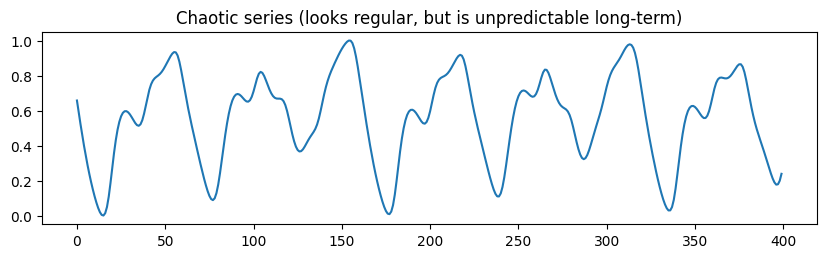

In [ ]:
def mackey_glass(n=2200, tau=17, beta=0.2, gamma=0.1, p=10, dt=1.0):
    x = np.full(n + tau, 1.2); rng = np.random.default_rng(0); x[:tau] += 0.05 * rng.standard_normal(tau)
    for t in range(tau, n + tau - 1):
        x[t + 1] = x[t] + dt * (beta * x[t - tau] / (1 + x[t - tau] ** p) - gamma * x[t])
    return x[tau + 200:]
series = mackey_glass(); series = (series - series.min()) / (series.max() - series.min())
plt.figure(figsize=(10, 2.5)); plt.plot(series[:400]); plt.title('Chaotic series (looks regular, but is unpredictable long-term)'); plt.show()

## 2. The quantum reservoir: 5 qubits, a fixed random circuit, no training
Each input window of 5 past values is written into 5 qubits; we then read out simple correlations (15 numbers).

In [ ]:
NQ = 5
bits = np.array([[(i >> (NQ - 1 - q)) & 1 for q in range(NQ)] for i in range(2 ** NQ)])
Zs = 1 - 2 * bits
pairs = [(i, j) for i in range(NQ) for j in range(i + 1, NQ)]

def reservoir_features(window, fixed):
    c = Circuit(NQ)
    for q in range(NQ): c.add(gates.RY(q, np.pi * window[q]))      # data in
    for l in range(3):
        for q in range(NQ): c.add(gates.RY(q, fixed[l, q, 0])); c.add(gates.RZ(q, fixed[l, q, 1]))
        for q in range(NQ): c.add(gates.CNOT(q, (q + 1) % NQ))
    p = c().probabilities()
    return np.concatenate([Zs.T @ p, [(Zs[:, i] * Zs[:, j]) @ p for i, j in pairs]])

HORIZON, W = 12, NQ                                     # predict 12 steps ahead from the last 5 values
idx = np.arange(W, len(series) - HORIZON)
Xraw = np.array([series[i - W:i] for i in idx]); yv = series[idx + HORIZON - 1]
ntr = 800; tr, te = slice(0, ntr), slice(ntr, ntr + 400)
nmse = lambda a, b: np.mean((a - b) ** 2) / np.var(b)

# 5 different random (untrained) quantum circuits
q_err, q_fits = [], []
for seed in range(5):
    fixed = np.random.default_rng(seed).uniform(0, 2*np.pi, (3, NQ, 2))
    F = np.array([reservoir_features(w, fixed) for w in Xraw])
    pred = Ridge(alpha=1e-4).fit(F[tr], yv[tr]).predict(F[te]); q_err.append(nmse(pred, yv[te])); q_fits.append(pred)
print("Quantum reservoir (5 random circuits) NMSE:", np.round(q_err, 3), " mean =", round(np.mean(q_err), 3))

Quantum reservoir (5 random circuits) NMSE: [0.25  0.227 0.19  0.216 0.205]  mean = 0.218


## 3. Fair comparison: classical baselines of every strength
Lower error = better.

Linear on raw window              : 0.315
Classical random features (15)    : 0.308  (range 0.225 to 0.476 over 10 draws)
Quantum reservoir (15 features)   : 0.218  (range 0.190 to 0.250 over 5 circuits)
Kernel ridge regression (classic) : 0.022


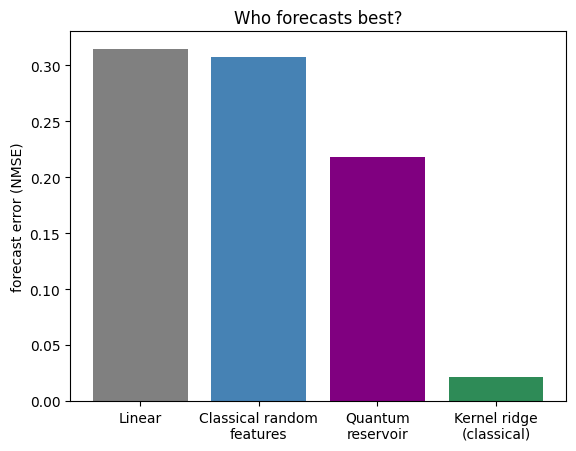

In [ ]:
# (a) simple linear model on the raw window
lin = Ridge(alpha=1e-4).fit(Xraw[tr], yv[tr]); e_lin = nmse(lin.predict(Xraw[te]), yv[te])
# (b) classical random features, same count (15), averaged over 10 random draws
e_rf = []
for s in range(10):
    r = np.random.default_rng(s); Wr = r.standard_normal((W, 15)) * 2; br = r.uniform(0, 2*np.pi, 15)
    F = np.tanh(Xraw @ Wr + br); e_rf.append(nmse(Ridge(alpha=1e-4).fit(F[tr], yv[tr]).predict(F[te]), yv[te]))
# (c) a strong, standard classical method: kernel ridge regression (tuned width)
e_krr = min(nmse(KernelRidge(kernel='rbf', gamma=g, alpha=1e-3).fit(Xraw[tr], yv[tr]).predict(Xraw[te]), yv[te]) for g in [5, 20, 50])
print(f"Linear on raw window              : {e_lin:.3f}")
print(f"Classical random features (15)    : {np.mean(e_rf):.3f}  (range {np.min(e_rf):.3f} to {np.max(e_rf):.3f} over 10 draws)")
print(f"Quantum reservoir (15 features)   : {np.mean(q_err):.3f}  (range {np.min(q_err):.3f} to {np.max(q_err):.3f} over 5 circuits)")
print(f"Kernel ridge regression (classic) : {e_krr:.3f}")
names = ['Linear', 'Classical random\nfeatures', 'Quantum\nreservoir', 'Kernel ridge\n(classical)']
vals = [e_lin, np.mean(e_rf), np.mean(q_err), e_krr]
plt.bar(names, vals, color=['gray', 'steelblue', 'purple', 'seagreen']); plt.ylabel('forecast error (NMSE)'); plt.title('Who forecasts best?'); plt.show()

## 4. See the forecasts

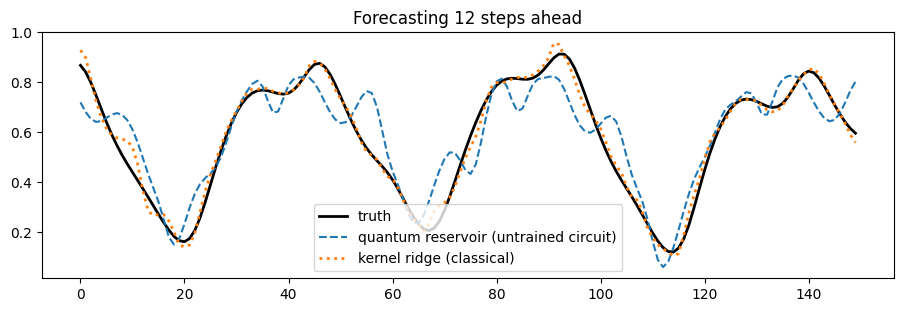

In [ ]:
kr = KernelRidge(kernel='rbf', gamma=20, alpha=1e-3).fit(Xraw[tr], yv[tr])
plt.figure(figsize=(11, 3.2)); plt.plot(yv[te][:150], 'k', lw=2, label='truth')
plt.plot(q_fits[0][:150], '--', label='quantum reservoir (untrained circuit)'); plt.plot(kr.predict(Xraw[te])[:150], ':', lw=2, label='kernel ridge (classical)'); plt.legend(); plt.title('Forecasting 12 steps ahead'); plt.show()

## 5. Discussion
* An *untrained* quantum circuit gives features good enough to beat a plain linear model. Training is cheap and avoids hard-to-train circuits.
* **But look at the numbers:** the quantum reservoir beats the *average* random classical features and is more consistent, yet the best classical random draws come close, and a standard classical kernel method is about ten times more accurate on this problem. Comparing only against weak baselines is a common source of overclaiming in papers.
* Where might quantum reservoirs matter? When the "reservoir" is a real physical quantum system (memory, speed, energy), or for quantum data. That is a hardware question, not shown here.
* **Try:** change `HORIZON` to 4 and 25; change the circuit depth (3 → 1); add more qubits (also change `NQ` and `W`).